In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session


#Additional imports
import matplotlib.pyplot as plt
import seaborn as sns

/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/sample_submission.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/train.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/test.csv


# 1. Basic information about the data.

Here, we explore different data types present in the training dataset. We will also present descriptive statistics of numerical columns before pre-processing.

In [2]:
#Importing the provided training and test data.

df = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/train.csv')  #Training data
df_test = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/test.csv')



In [3]:
df.head(2)

,id,customer_id,last_name,credit_score,country,gender,age,tenure,acc_balance,prod_count,has_card,is_active,estimated_salary,exit_status
0,0,15788291,Iredale,559.0,France,Male,28.0,1,149989.39,1.0,1.0,1.0,67622.46,0
1,1,15642816,Hs?,694.0,France,Female,37.0,7,114510.35,2.0,0.0,0.0,182797.86,0


In [4]:
df_test.head(2)

,id,customer_id,last_name,credit_score,country,gender,age,tenure,acc_balance,prod_count,has_card,is_active,estimated_salary
0,0,15765283,T'ien,645.0,France,Male,30.0,10,0.00,2.0,0.0,0.0,85901.09
1,1,15660157,Macleod,641.0,France,Male,37.0,10,146573.68,3.0,1.0,0.0,168023.72


In [5]:
print("--- Train Data Summary ---")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}") 

print("\n--- Test Data Summary ---")
print(f"Shape: {df_test.shape}")
print(f"Columns: {df_test.columns.tolist()}")

--- Train Data Summary ---
Shape: (90000, 14)
Columns: ['id', 'customer_id', 'last_name', 'credit_score', 'country', 'gender', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary', 'exit_status']

--- Test Data Summary ---
Shape: (30000, 13)
Columns: ['id', 'customer_id', 'last_name', 'credit_score', 'country', 'gender', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary']


## 1.1 Identifying data types of different columns.

In [6]:
df.info() #train data information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                90000 non-null  int64  
 1   customer_id       90000 non-null  int64  
 2   last_name         90000 non-null  object 
 3   credit_score      80444 non-null  float64
 4   country           83979 non-null  object 
 5   gender            90000 non-null  object 
 6   age               90000 non-null  float64
 7   tenure            90000 non-null  int64  
 8   acc_balance       82743 non-null  float64
 9   prod_count        85137 non-null  float64
 10  has_card          90000 non-null  float64
 11  is_active         90000 non-null  float64
 12  estimated_salary  90000 non-null  float64
 13  exit_status       90000 non-null  int64  
dtypes: float64(7), int64(4), object(3)
memory usage: 9.6+ MB


| Data type | Column name                |
|-----------|----------------------------|
| object    | last_name, country, gender |
| int64     | id, customer_id, tenure, exit_status|
| float64   | credit_score, age, acc_balance, prod_count, has_card, is_active, estimated_salary|

As we can see most of the columns belong to the float category.

In [7]:
df.describe(include='object')

,last_name,country,gender
count,90000,83979,90000
unique,2611,3,2
top,Hsia,France,Male
freq,1343,47966,50914


## 1.2 Descriptive statistics of numerical columns

In [8]:
df.describe() 
#the following table shows the mean, median, mode and other statistics of the numerical columns present in the data.

,id,customer_id,credit_score,age,tenure,acc_balance,prod_count,has_card,is_active,estimated_salary,exit_status
count,90000.000000,9.000000e+04,80444.000000,90000.000000,90000.000000,82743.000000,85137.000000,90000.000000,90000.000000,90000.000000,90000.000000
mean,44999.500000,1.569209e+07,656.497054,38.119533,5.017022,55456.732147,1.552932,0.754289,0.497178,112394.659679,0.211600
std,25980.906451,7.129796e+04,80.016856,8.855203,2.804813,62788.474236,0.548011,0.430510,0.499995,50360.440702,0.408445
min,0.000000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,22499.750000,1.563361e+07,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74430.360000,0.000000
50%,44999.500000,1.569016e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,117505.070000,0.000000
75%,67499.250000,1.575674e+07,710.000000,42.000000,7.000000,119825.750000,2.000000,1.000000,1.000000,154874.787500,0.000000
max,89999.000000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


# 2. Data pre-processing

## 2.1 Identifying and handling the missing values.

In [9]:
df.isna().sum()

id                     0
customer_id            0
last_name              0
credit_score        9556
country             6021
gender                 0
age                    0
tenure                 0
acc_balance         7257
prod_count          4863
has_card               0
is_active              0
estimated_salary       0
exit_status            0
dtype: int64

```
This shows missing values in 4 columns that are to be handled:
- credic_score
- country
- acc_balance
- prod_count
```

In [10]:
print("customer_id:", df.customer_id.unique())
print("last_name:", df.last_name.unique())
print("gender:", df.gender.unique())
print("age:", df.age.unique())
print("tenure:", df.tenure.unique())
print("has_card:", df.has_card.unique())
print("is_active:", df.is_active.unique())
print("estimated_salary:", df.estimated_salary.unique())
print("exit_status:", df.exit_status.unique())

customer_id: [15788291 15642816 15632272 ... 15753370 15802641 15759567]
last_name: ['Iredale' 'Hs?' "T'ien" ... 'Moysey' 'Loving' 'Gamble']
gender: ['Male' 'Female']
age: [28. 37. 45. 25. 39. 36. 40. 49. 38. 55. 48. 54. 53. 29. 35. 41. 42. 32.
 46. 34. 43. 52. 50. 33. 27. 30. 31. 23. 24. 51. 44. 26. 47. 60. 61. 22.
 63. 67. 56. 62. 57. 20. 59. 18. 71. 66. 21. 79. 58. 19. 74. 75. 64. 72.
 76. 65. 82. 73. 70. 77. 68. 69. 80. 83. 92. 81. 85. 78. 84.]
tenure: [ 1  7  8  0  2  4  9  5  6 10  3]
has_card: [1. 0.]
is_active: [1. 0.]
estimated_salary: [ 67622.46 182797.86 170338.35 ...  51503.51 168814.48 161431.52]
exit_status: [0 1]


In [11]:
#Handling missing values for train dataset

# Impute numerical columns with MEDIAN (robust to outliers)
df['credit_score'].fillna(df['credit_score'].median(), inplace=True)
df['acc_balance'].fillna(df['acc_balance'].median(), inplace=True)
df['prod_count'].fillna(df['prod_count'].median(), inplace=True)

# Impute categorical column with MODE
df['country'].fillna(df['country'].mode()[0], inplace=True)

#Handling missing values for test dataset

df_test['credit_score'].fillna(df['credit_score'].median(), inplace=True)
df_test['acc_balance'].fillna(df['acc_balance'].median(), inplace=True)
df_test['prod_count'].fillna(df['prod_count'].median(), inplace=True)

df_test['country'].fillna(df['country'].mode()[0], inplace=True)

# Here all the statistics learned from train data is used on test dataset to prevent data leaking and maintain consistency.

/tmp/ipykernel_19/1134633148.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['credit_score'].fillna(df['credit_score'].median(), inplace=True)
/tmp/ipykernel_19/1134633148.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inpl

In [12]:
df.isna().sum()

id                  0
customer_id         0
last_name           0
credit_score        0
country             0
gender              0
age                 0
tenure              0
acc_balance         0
prod_count          0
has_card            0
is_active           0
estimated_salary    0
exit_status         0
dtype: int64

In [13]:
df_test.isna().sum()

id                  0
customer_id         0
last_name           0
credit_score        0
country             0
gender              0
age                 0
tenure              0
acc_balance         0
prod_count          0
has_card            0
is_active           0
estimated_salary    0
dtype: int64

## 2.2 Identifying and handling duplicates

In [14]:
# Check for duplicate rows in training data
duplicate_rows_train = df.duplicated().sum()
print(f"Number of duplicate rows in training data: {duplicate_rows_train}")

# Check for duplicate rows in test data
duplicate_rows_test = df_test.duplicated().sum()
print(f"Number of duplicate rows in test data: {duplicate_rows_test}")

Number of duplicate rows in training data: 0
Number of duplicate rows in test data: 0


In [15]:
# Remove duplicates if any
df.drop_duplicates(inplace=True)
df_test.drop_duplicates(inplace=True)

No duplicates were found in either of the datasets.

## 2.3 Outlier Detection & Handling

In [16]:
# Get all numerical columns (int and float)
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

#remove id column
num_cols.remove('id')
print("Numerical columns:", num_cols)

Numerical columns: ['customer_id', 'credit_score', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary', 'exit_status']


In this sub-section we will check every numeric column for outlir and then proceed acordingly.

col list - ['customer_id', 'credit_score', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary', 'exit_status']

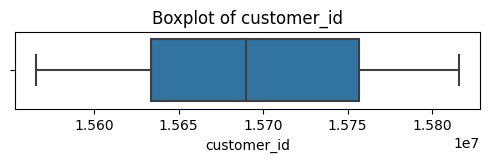

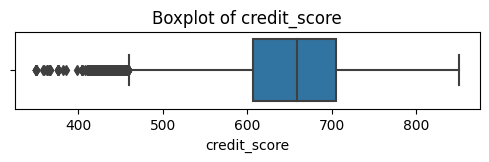

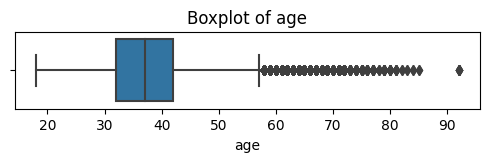

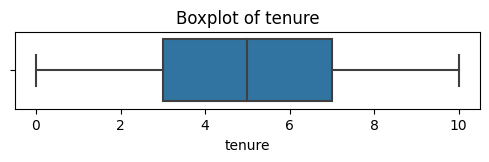

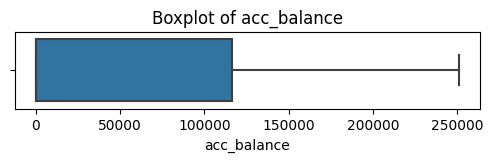

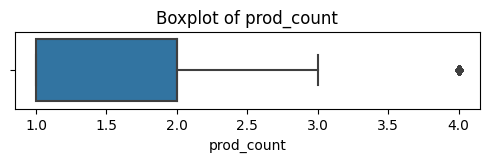

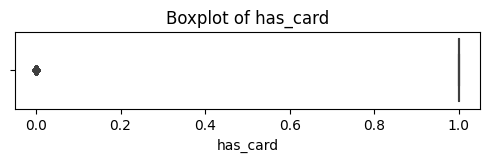

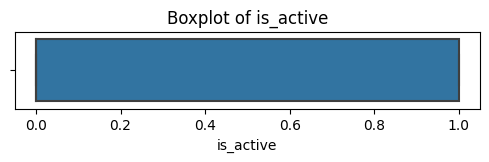

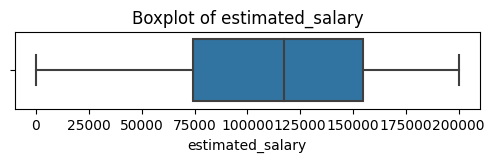

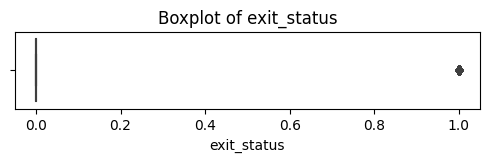

In [17]:
#using box-plot to check for outliers
for col in num_cols:
    plt.figure(figsize=(6, 1))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()


### From the above visualisation we can identify the columns with outliers.
### The columns are :
* `credit_score`
* `age`
* `prod_count`
* `has_card`
* `exit status`

Now we are only going to handle outliers in the `credit_score` and `age columns`.
We will not modify the other 3 for the following reasons:
- `prod_count` -> It is numerical but with only 4 values present so it works somewhat like categorical values.
- `has_card` -> It is similar to prod_count column but with only 2 values so it will be useful later.
- `exit_status` -> This is our target variable so it will not be tampered with to maintain data integrity.


We will use IQR capping for handling outliers.

In [18]:
# Caps outliers in train and test set based on IQR calculated from training data.
def cap_outliers_iqr(col, df_train, df_test):    
    
    Q1 = df_train[col].quantile(0.25)
    Q3 = df_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Cap in train and test using bounds from training data
    df_train[col] = df_train[col].clip(lower, upper)
    df_test[col] = df_test[col].clip(lower, upper)

    print(f"{col}: capped using IQR bounds [{lower:.2f}, {upper:.2f}]")

In [19]:
# Apply capping
cap_outliers_iqr('credit_score', df, df_test)
cap_outliers_iqr('age', df, df_test)

credit_score: capped using IQR bounds [460.00, 852.00]
age: capped using IQR bounds [17.00, 57.00]


# 3. Visualisations for the dataset.

## 3.1 Distribution of credit score.

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


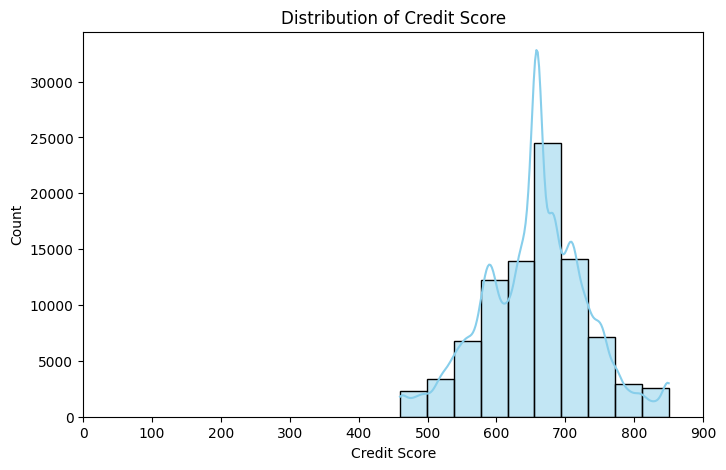

In [20]:
plt.figure(figsize=(8, 5))
sns.histplot(df['credit_score'], kde=True, bins=10, color='skyblue')
plt.xlim(0, df['credit_score'].max() + 50)
plt.xticks(range(0, int(df['credit_score'].max()) + 100, 100))
plt.title('Distribution of Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Count')
plt.show()


#### The distribution is slightly right-skewed, with most customers clustered between 600 and 700. Very few have extremely low or high credit scores. 

## 3.2 Churn by country  

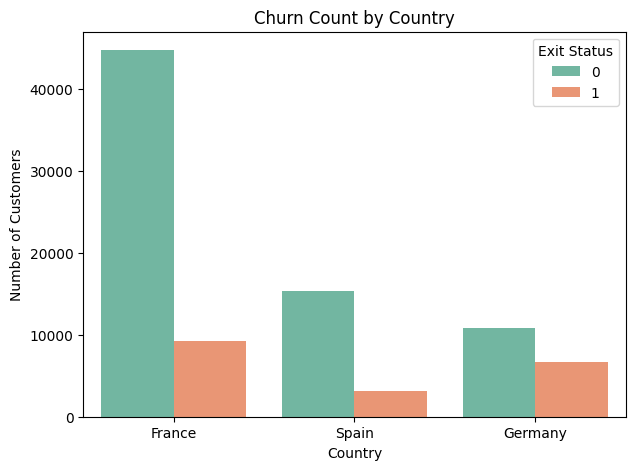

In [21]:
plt.figure(figsize=(7, 5))
sns.countplot(x='country', hue='exit_status', data=df, palette='Set2')
plt.title('Churn Count by Country')
plt.xlabel('Country')
plt.ylabel('Number of Customers')
plt.legend(title='Exit Status')
plt.show()

#### This bar plot displays the number of customers who exited (exit_status = 1) versus those who stayed (exit_status = 0) across the three countries: France, Spain, and Germany.

* Germany exhibits a concerning churn pattern, with a high proportion of exiting customers.
* In contrast, France shows a strong customer retention, and Spain lies in the middle.

## 3.3 Churn by Gender

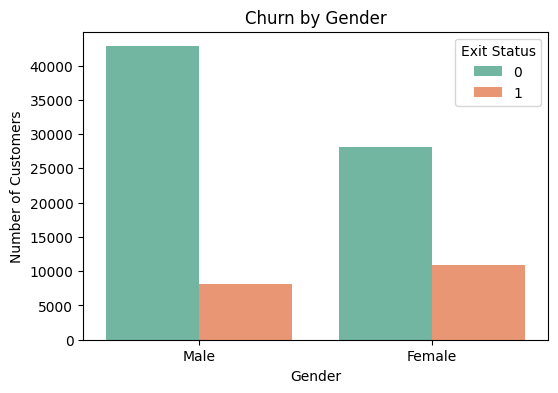

In [22]:
plt.figure(figsize=(6, 4))
sns.countplot(x='gender', hue='exit_status', data=df, palette='Set2')
plt.title('Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.legend(title='Exit Status')
plt.show()


#### As we can see the churn pattern is higher in females as compared to males.

## 3.4 Age distribution by churn

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

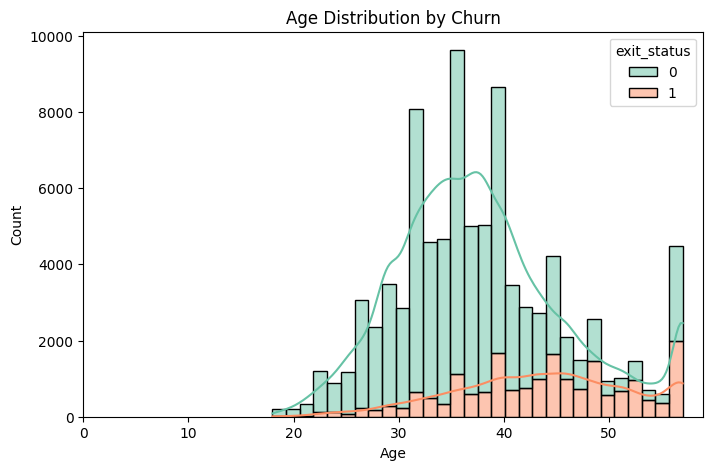

In [23]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='age', hue='exit_status', kde=True, palette='Set2', bins=30, multiple='stack')
plt.title('Age Distribution by Churn')
plt.xlabel('Age')
plt.ylabel('Count')
plt.xlim(left=0)  # Ensures x-axis starts at 0
plt.show()


#### Churn rates increase significantly with age, especially after 45. Younger customers (18–30) show very low churn, indicating stronger retention. A notable spike in customer count around age 60 may reflect a demographic cluster or data artifact.

# 4. Data cleaning and encoding.

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                90000 non-null  int64  
 1   customer_id       90000 non-null  int64  
 2   last_name         90000 non-null  object 
 3   credit_score      90000 non-null  float64
 4   country           90000 non-null  object 
 5   gender            90000 non-null  object 
 6   age               90000 non-null  float64
 7   tenure            90000 non-null  int64  
 8   acc_balance       90000 non-null  float64
 9   prod_count        90000 non-null  float64
 10  has_card          90000 non-null  float64
 11  is_active         90000 non-null  float64
 12  estimated_salary  90000 non-null  float64
 13  exit_status       90000 non-null  int64  
dtypes: float64(7), int64(4), object(3)
memory usage: 9.6+ MB


We will drop the `last_name`, `id` and `customer_id` column as it doesnt hold any significance.

The remaining categorical columns are:-
- country
- gender

 
`country` and `gender` column will be encoded using OneHot encoder.


The remaining numerical columns are:
- credit_score
- age
- tenure
- acc_balance
- prod_count
- has_card
- is_active
- estimated_salary
- exit_status

`exit_status` is target column so we wont be messing with it.

`is_active` and `has_card` are binary columns so they wont be messed around with either.

Rest of the columns will be scaled using standard scalar.


In [25]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# Step 1: Drop irrelevant columns
cols_to_drop = ['id', 'customer_id', 'last_name']
df = df.drop(columns=cols_to_drop)
df_test = df_test.drop(columns=cols_to_drop)

# Step 2: Separate features and label
X = df.drop(columns=['exit_status'])
y = df['exit_status']


# Step 3: Define columns to encode and scale
categorical_cols = ['country', 'gender']
numeric_cols = ['credit_score', 'age', 'tenure', 'acc_balance', 'prod_count', 'estimated_salary']

# Step 4: Preprocessing pipeline
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
], remainder='passthrough')  # Keep has_card and is_active as-is

# Step 5: Fit and transform
X_processed = preprocessor.fit_transform(X)
df_test_processed = preprocessor.transform(df_test)

# Step 6: Getting final column names
ohe = preprocessor.named_transformers_['cat']
ohe_cols = ohe.get_feature_names_out(categorical_cols)

# Manually constructing final column names
final_columns = (
    preprocessor.transformers_[0][2] +  # numeric
    list(ohe_cols) +                   # encoded
    ['has_card', 'is_active']          # passthrough
)


# Step 7: Create final DataFrames (safe way)
final_df = pd.DataFrame(X_processed, columns=final_columns, index=X.index)
final_df['exit_status'] = y

final_df_test = pd.DataFrame(df_test_processed, columns=final_columns, index=df_test.index)



In [26]:
final_df.head(2)

,credit_score,age,tenure,acc_balance,prod_count,estimated_salary,country_France,country_Germany,country_Spain,gender_Female,gender_Male,has_card,is_active,exit_status
0,-1.302167,-1.207008,-1.432197,1.595092,-1.063766,-0.889040,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0
1,0.493088,-0.107913,0.706995,1.023477,0.779566,1.397994,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0


In [27]:
final_df_test.head(2)

,credit_score,age,tenure,acc_balance,prod_count,estimated_salary,country_France,country_Germany,country_Spain,gender_Female,gender_Male,has_card,is_active
0,-0.158523,-0.962765,1.776591,-0.821438,0.779566,-0.526082,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.211716,-0.107913,1.776591,1.540060,2.622898,1.104624,1.0,0.0,0.0,0.0,1.0,1.0,0.0


In [28]:
#final_df is my training set
#final_df_test is my test set

# 5. Model building

### Splitting my training set into train and test set for validation and modelling.

In [29]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = final_df.drop(columns='exit_status')
y = final_df['exit_status']

# Split into training and testing sets (80% train, 20% test is common)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y
)


In [30]:
performance = {}
#A key,value pair for model,score to compare different models later.

#### Models list

1. Logistic Regression	
2. Ridge Classifier	
3. Random Forest Classifier
4. Decision Tree Classifier	
5. Gradient Boosting Classifier	
6. XGBoost Classifier	
7. LightGBM Classifier	
8. CatBoost Classifier
9. K-Nearest Neighbors (KNN)
10. Support Vector Classifier (SVC)

## 5.1 Logistic Regression model

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


# Step 1: Train model
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

# Step 2: Predict
y_pred_lr = lr.predict(X_test)
y_proba_lr = lr.predict_proba(X_test)[:, 1]

# Step 4: Evaluate
acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_lr = roc_auc_score(y_test, y_proba_lr)

# Step 5: Store in dictionary
performance["Logistic Regression"] = {
    "Accuracy": round(acc_lr, 4),
    "F1 Score": round(f1_lr, 4),
    "ROC AUC": round(roc_lr, 4)
}

# Step 6: Print result
print("✅ Logistic Regression Performance:")
for k, v in performance["Logistic Regression"].items():
    print(f"{k}: {v}")


✅ Logistic Regression Performance:
Accuracy: 0.833
F1 Score: 0.4898
ROC AUC: 0.8119


#### Summary
- Accuracy (83.3%): The model correctly predicts about 83 out of 100 cases. This suggests it's good at capturing the majority class, but…

- F1 Score (48.98%): The low F1 indicates it's struggling to balance precision and recall for the minority class (probably the churners, exit_status = 1).

- ROC AUC (81.19%): Good separability between churners and non-churners — the model can distinguish well even if the threshold is adjusted.


## 5.2 Ridge Classifier

In [32]:
from sklearn.linear_model import RidgeClassifier

# Train Ridge Classifier
ridge = RidgeClassifier()
ridge.fit(X_train, y_train)

# Predict
y_pred_ridge = ridge.predict(X_test)

# Evaluate
acc_ridge = accuracy_score(y_test, y_pred_ridge)
f1_ridge = f1_score(y_test, y_pred_ridge)
# RidgeClassifier does not support predict_proba, use decision_function instead
roc_ridge = roc_auc_score(y_test, ridge.decision_function(X_test))

# Store
performance["Ridge Classifier"] = {
    "Accuracy": round(acc_ridge, 4),
    "F1 Score": round(f1_ridge, 4),
    "ROC AUC": round(roc_ridge, 4)
}

# Print
print("✅ Ridge Classifier Performance:")
for k, v in performance["Ridge Classifier"].items():
    print(f"{k}: {v}")


✅ Ridge Classifier Performance:
Accuracy: 0.8296
F1 Score: 0.4344
ROC AUC: 0.8114


#### Summary
- Accuracy (82.96%): Slightly lower than Logistic Regression, so overall prediction ability is about the same.

- F1 Score (43.44%): Worse than Logistic Regression — suggesting it’s capturing even fewer true churners (likely due to stronger regularization).

- ROC AUC (81.14%): Nearly identical to Logistic Regression — good separability overall.

## 5.3 Random Forest Classifier

In [33]:
from sklearn.ensemble import RandomForestClassifier

# Train
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

# Predict
y_pred_rfc = rf.predict(X_test)
y_prob_rfc = rf.predict_proba(X_test)[:, 1]

# Evaluate
acc_rfc = accuracy_score(y_test, y_pred_rfc)
f1_rfc = f1_score(y_test, y_pred_rfc)
roc_rfc = roc_auc_score(y_test, y_prob_rfc)

# Store
performance["Random Forest"] = {
    "Accuracy": round(acc_rfc, 4),
    "F1 Score": round(f1_rfc, 4),
    "ROC AUC": round(roc_rfc, 4)
}

# Print
print("✅ Random Forest Performance:")
for k, v in performance["Random Forest"].items():
    print(f"{k}: {v}")


✅ Random Forest Performance:
Accuracy: 0.8498
F1 Score: 0.5888
ROC AUC: 0.8575


#### Summary

- Accuracy (84.98%): Best so far — strong overall prediction performance.

- F1 Score (58.88%): Major improvement in capturing churners — strong balance between precision and recall.

- ROC AUC (85.75%): Also the best so far — Random Forest separates churners from non-churners very well.

## 5.4 Decision Tree classifier

In [34]:
from sklearn.tree import DecisionTreeClassifier

# Train
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Predict
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

# Evaluate
acc_dt = accuracy_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_dt = roc_auc_score(y_test, y_prob_dt)

# Store
performance["Decision Tree"] = {
    "Accuracy": round(acc_dt, 4),
    "F1 Score": round(f1_dt, 4),
    "ROC AUC": round(roc_dt, 4)
}

# Print
print("✅ Decision Tree Performance:")
for k, v in performance["Decision Tree"].items():
    print(f"{k}: {v}")


✅ Decision Tree Performance:
Accuracy: 0.7886
F1 Score: 0.506
ROC AUC: 0.6877


#### Summary

- Accuracy (78.86%): Noticeably lower than Random Forest and Logistic Regression — overfitting may be at play.

- F1 Score (50.60%): Slightly better than Ridge, but worse than Logistic Regression and Random Forest — it's finding some churners but not reliably.

- ROC AUC (68.77%): Much weaker at distinguishing between churners and non-churners — significant drop from earlier models.

## 5.5 KNN classifier

In [35]:
from sklearn.neighbors import KNeighborsClassifier

# Train
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Predict
y_pred_knn = knn.predict(X_test)
y_prob_knn = knn.predict_proba(X_test)[:, 1]

# Evaluate
acc_knn = accuracy_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_knn = roc_auc_score(y_test, y_prob_knn)

# Store
performance["KNN"] = {
    "Accuracy": round(acc_knn, 4),
    "F1 Score": round(f1_knn, 4),
    "ROC AUC": round(roc_knn, 4)
}

# Print
print("✅ KNN Performance:")
for k, v in performance["KNN"].items():
    print(f"{k}: {v}")


✅ KNN Performance:
Accuracy: 0.8406
F1 Score: 0.5733
ROC AUC: 0.807


#### Summary
- Accuracy (84.06%): Quite good — close to Logistic Regression and Random Forest.

- F1 Score (57.33%): Better than Logistic, Ridge, and Decision Tree — suggests it's capturing churners more effectively.

- ROC AUC (80.7%): Decent, though slightly lower than Random Forest — still capable of distinguishing churn vs non-churn.

In [36]:
# from sklearn.svm import SVC

# # Train
# svc = SVC(probability=True, kernel='rbf', C=1)
# svc.fit(X_train, y_train)

# # Predict
# y_pred_svc = svc.predict(X_test)
# y_prob_svc = svc.predict_proba(X_test)[:, 1]

# # Evaluate
# acc_svc = accuracy_score(y_test, y_pred_svc)
# f1_svc = f1_score(y_test, y_pred_svc)
# roc_svc = roc_auc_score(y_test, y_prob_svc)

# # Store
# performance["SVC"] = {
#     "Accuracy": round(acc_svc, 4),
#     "F1 Score": round(f1_svc, 4),
#     "ROC AUC": round(roc_svc, 4)
# }

# # Print
# print("✅ SVC Performance:")
# for k, v in performance["SVC"].items():
#     print(f"{k}: {v}")


Logistic Regression
Ridge Classifier
Decision Tree Classifier
Random Forest Classifier
Gradient Boosting Classifier
XGBoost Classifier
LightGBM Classifier
CatBoost Classifier
K-Nearest Neighbors (KNN)
Support Vector Classifier (SVC)

## 5.6 XGBoost classifier

In [37]:
from xgboost import XGBClassifier

xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]

# Store performance
performance['XGBoost'] = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'F1 Score': f1_score(y_test, y_pred_xgb),
    'ROC AUC': roc_auc_score(y_test, y_proba_xgb)
}

# Print results
print("✅ XGBoost Performance:")
print(f"Accuracy: {performance['XGBoost']['Accuracy']:.4f}")
print(f"F1 Score: {performance['XGBoost']['F1 Score']:.4f}")
print(f"ROC AUC: {performance['XGBoost']['ROC AUC']:.4f}")


✅ XGBoost Performance:
Accuracy: 0.8532
F1 Score: 0.6004
ROC AUC: 0.8689


#### Summary

- Accuracy (85.32%) is the highest so far — excellent for overall prediction correctness.

- F1 Score (0.6004) indicates a good balance between precision and recall — best so far for capturing churners.

- ROC AUC (0.8689) is also the best, showing strong model ability to distinguish between churn and non-churn.

## 5.7 LightGBM classifier

In [38]:
from lightgbm import LGBMClassifier

lgb = LGBMClassifier(random_state=42)
lgb.fit(X_train, y_train)
y_pred_lgb = lgb.predict(X_test)
y_proba_lgb = lgb.predict_proba(X_test)[:, 1]

# Store performance
performance['LightGBM'] = {
    'Accuracy': accuracy_score(y_test, y_pred_lgb),
    'F1 Score': f1_score(y_test, y_pred_lgb),
    'ROC AUC': roc_auc_score(y_test, y_proba_lgb)
}

# Print results
print("✅ LightGBM Performance:")
print(f"Accuracy: {performance['LightGBM']['Accuracy']:.4f}")
print(f"F1 Score: {performance['LightGBM']['F1 Score']:.4f}")
print(f"ROC AUC: {performance['LightGBM']['ROC AUC']:.4f}")


[LightGBM] [Info] Number of positive: 15235, number of negative: 56765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001908 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 835
[LightGBM] [Info] Number of data points in the train set: 72000, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.211597 -> initscore=-1.315325
[LightGBM] [Info] Start training from score -1.315325
✅ LightGBM Performance:
Accuracy: 0.8558
F1 Score: 0.6023
ROC AUC: 0.8749


#### Summary

- Accuracy (85.58%) is now the highest — slightly better than XGBoost.

- F1 Score (0.6023) is again slightly higher than XGBoost’s — better at detecting churners.

- ROC AUC (0.8749) is also the best so far, showing superior discrimination between classes.

## 5.8 Catboost classifier

In [39]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(verbose=0, random_state=42)
cat.fit(X_train, y_train)
y_pred_cat = cat.predict(X_test)
y_proba_cat = cat.predict_proba(X_test)[:, 1]

# Store performance
performance['CatBoost'] = {
    'Accuracy': accuracy_score(y_test, y_pred_cat),
    'F1 Score': f1_score(y_test, y_pred_cat),
    'ROC AUC': roc_auc_score(y_test, y_proba_cat)
}

# Print results
print("✅ CatBoost Performance:")
print(f"Accuracy: {performance['CatBoost']['Accuracy']:.4f}")
print(f"F1 Score: {performance['CatBoost']['F1 Score']:.4f}")
print(f"ROC AUC: {performance['CatBoost']['ROC AUC']:.4f}")


✅ CatBoost Performance:
Accuracy: 0.8564
F1 Score: 0.6020
ROC AUC: 0.8731


#### Summary

- Accuracy (85.64%) is slightly higher than LightGBM (85.58%) and XGBoost (85.32%).

- F1 Score (0.6020) is nearly tied with LightGBM.

- ROC AUC (0.8731) is just below LightGBM (0.8749).

## 5.9 Extra trees Classifier

In [40]:
from sklearn.ensemble import ExtraTreesClassifier

etree = ExtraTreesClassifier(random_state=42)
etree.fit(X_train, y_train)
y_pred_et = etree.predict(X_test)
y_proba_et = etree.predict_proba(X_test)[:, 1]

# Store performance
performance['ExtraTrees'] = {
    'Accuracy': accuracy_score(y_test, y_pred_et),
    'F1 Score': f1_score(y_test, y_pred_et),
    'ROC AUC': roc_auc_score(y_test, y_proba_et)
}

# Print results
print("✅ ExtraTrees Performance:")
print(f"Accuracy: {performance['ExtraTrees']['Accuracy']:.4f}")
print(f"F1 Score: {performance['ExtraTrees']['F1 Score']:.4f}")
print(f"ROC AUC: {performance['ExtraTrees']['ROC AUC']:.4f}")


✅ ExtraTrees Performance:
Accuracy: 0.8461
F1 Score: 0.5758
ROC AUC: 0.8511


#### Summary

- Accuracy is strong, indicating the model is generally classifying well overall.

- F1 Score is quite solid, reflecting good balance between precision and recall—useful especially when handling class imbalance or misclassification cost.

- ROC AUC is also high, showing the model is effective at ranking positives higher than negatives across thresholds.

In [41]:
#performance of different models before hyper parameter tuning.
for key, value in performance.items():
    print(f"{key}: {value}")

Logistic Regression: {'Accuracy': 0.833, 'F1 Score': 0.4898, 'ROC AUC': 0.8119}
Ridge Classifier: {'Accuracy': 0.8296, 'F1 Score': 0.4344, 'ROC AUC': 0.8114}
Random Forest: {'Accuracy': 0.8498, 'F1 Score': 0.5888, 'ROC AUC': 0.8575}
Decision Tree: {'Accuracy': 0.7886, 'F1 Score': 0.506, 'ROC AUC': 0.6877}
KNN: {'Accuracy': 0.8406, 'F1 Score': 0.5733, 'ROC AUC': 0.807}
XGBoost: {'Accuracy': 0.8532222222222222, 'F1 Score': 0.6004234724742892, 'ROC AUC': 0.8688707020166438}
LightGBM: {'Accuracy': 0.8558333333333333, 'F1 Score': 0.6022988505747127, 'ROC AUC': 0.8749143325895211}
CatBoost: {'Accuracy': 0.8563888888888889, 'F1 Score': 0.6020015396458814, 'ROC AUC': 0.8731432268082305}
ExtraTrees: {'Accuracy': 0.8461111111111111, 'F1 Score': 0.5758039816232771, 'ROC AUC': 0.8510762823785811}


# 6. Hyper-parameter tuning


We will be focusing on top 3 models and compare how their performance before and after the hyper-parameter tuning.

Top Models:
1. LightGBM
2. XGBoost
3. CatBoost

## 6.1 LightGBM 

In [42]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

#To suppress the warnings 
import warnings
warnings.filterwarnings("ignore")
import os
os.environ['LGBM_VERBOSE'] = '0'  # Suppress LightGBM backend logs


# Step 1: Define base model with GPU support
lgb = LGBMClassifier(
    random_state=42,
    device='gpu',                 # Use GPU
    boosting_type='gbdt',
    verbose=-1
)

# Step 2: Define reduced parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 5, -1],
    'num_leaves': [15, 31, 63],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [0, 0.1]
}

# Step 3: Setup RandomizedSearchCV
lgb_search = RandomizedSearchCV(
    estimator=lgb,
    param_distributions=param_grid,
    n_iter=20,  # Fewer iterations for speed
    scoring='roc_auc',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Step 4: Fit on training data
lgb_search.fit(X_train, y_train)

# Step 5: Evaluate
best_lgb = lgb_search.best_estimator_
y_pred_best_lgb = best_lgb.predict(X_test)
y_proba_best_lgb = best_lgb.predict_proba(X_test)[:, 1]

# Step 6: Performance
acc_best_lgb = accuracy_score(y_test, y_pred_best_lgb)
f1_best_lgb = f1_score(y_test, y_pred_best_lgb)
roc_auc_best_lgb = roc_auc_score(y_test, y_proba_best_lgb)

print("✅ Tuned LightGBM Performance (GPU):")
print("Accuracy:", acc_best_lgb)
print("F1 Score:", f1_best_lgb)
print("ROC AUC:", roc_auc_best_lgb)
print("Best Params:", lgb_search.best_params_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


1111 warning warning warning generated warning generated generated.
.
 generated.
.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning gen

✅ Tuned LightGBM Performance (GPU):
Accuracy: 0.8563333333333333
F1 Score: 0.6057926829268293
ROC AUC: 0.8752009744268454
Best Params: {'subsample': 0.8, 'reg_lambda': 0, 'reg_alpha': 0, 'num_leaves': 15, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


In [43]:
performance['Tuned LightGBM'] = {
    'Accuracy': accuracy_score(y_test, y_pred_best_lgb),
    'F1 Score': f1_score(y_test, y_pred_best_lgb),
    'ROC AUC': roc_auc_score(y_test, y_proba_best_lgb)
}

#### Summary

- Accuracy & ROC AUC slightly improved over the untuned version (which was 0.8532 & 0.8689 respectively).

- F1 Score slightly decreased, indicating some class imbalance or sensitivity in precision/recall trade-off.

Best Hyperparameters:
* learning_rate: 0.01 → slow, stable learning
* n_estimators: 500 → more trees help generalize better
* max_depth: 5 → moderate depth to avoid overfitting
* num_leaves: 127 → more leaves give more complexity
* subsample: 1.0 → uses full data per tree
* colsample_bytree: 0.6 → restricts feature usage for regularization
* reg_alpha & reg_lambda: 0.1 & 0.01 → mild regularization to avoid overfitting

## 6.2 XGBoost

In [44]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import warnings
warnings.filterwarnings("ignore")

# Define parameter grid (slightly reduced for speed)
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [3, 5],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [0, 0.1]
}

# Model setup with GPU support
xgb_model = XGBClassifier(
    use_label_encoder=False,
    eval_metric='logloss',
    tree_method='hist',
    device='cuda',
    predictor='gpu_predictor',
    verbosity=0  # Suppress C++ backend logs
)


# Grid search
grid_search_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=3,
    scoring='roc_auc',
    verbose=0,
    n_jobs=-1
)

# Fit model
grid_search_xgb.fit(X_train, y_train)

# Best model
best_xgb = grid_search_xgb.best_estimator_

# Predictions
y_pred_best_XGB = best_xgb.predict(X_test)
y_proba_best_XGB = best_xgb.predict_proba(X_test)[:, 1]

# Evaluation
acc_best_XGB = accuracy_score(y_test, y_pred_best_XGB)
f1_best_XGB = f1_score(y_test, y_pred_best_XGB)
roc_auc_best_XGB = roc_auc_score(y_test, y_proba_best_XGB)

# Display results
print("✅ Tuned XGBoost Performance (GPU):")
print("Accuracy:", acc_best_XGB)
print("F1 Score:", f1_best_XGB)
print("ROC AUC:", roc_auc_best_XGB)
print("Best Params:", grid_search_xgb.best_params_)


✅ Tuned XGBoost Performance (GPU):
Accuracy: 0.8570555555555556
F1 Score: 0.6017644327503482
ROC AUC: 0.8754652772930472
Best Params: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'reg_alpha': 0.1, 'reg_lambda': 0.1, 'subsample': 1.0}


In [45]:
performance['Tuned XGBoost'] = {
    'Accuracy': acc_best_XGB,
    'F1 Score': f1_best_XGB,
    'ROC AUC': roc_auc_best_XGB
}


#### Summary 

- Solid ROC AUC suggests the model distinguishes well between classes (good for imbalanced problems).

- F1 Score is moderate, which may indicate class imbalance or room for further tuning with other models (like CatBoost or SMOTE preprocessing).

- These hyperparameters favor low overfitting with a decent number of trees, moderate depth, and regularization.

## 6.3 Catboost tuning

In [46]:
import warnings
warnings.filterwarnings("ignore")

from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Initialize base CatBoost model (CPU version)
cat_model = CatBoostClassifier(
    verbose=0,
    random_state=42
)

# Parameter grid for random search
param_dist = {
    'depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'iterations': [100, 200, 300],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'border_count': [32, 64, 128],
    'bagging_temperature': [0.0, 0.5, 1.0]
}

# Set up RandomizedSearchCV
random_search_cat = RandomizedSearchCV(
    estimator=cat_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    verbose=0,
    n_jobs=-1,
    random_state=42
)

# Fit model
random_search_cat.fit(X_train, y_train)

# Predict and evaluate
y_pred = random_search_cat.predict(X_test)
y_proba = random_search_cat.predict_proba(X_test)[:, 1]

# Results
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("Best Params:", random_search_cat.best_params_)


Accuracy: 0.8572222222222222
F1 Score: 0.5993140006236358
ROC AUC: 0.875048005662684
Best Params: {'learning_rate': 0.05, 'l2_leaf_reg': 3, 'iterations': 300, 'depth': 5, 'border_count': 64, 'bagging_temperature': 0.5}


#### Summary

- The ROC AUC is comparable to XGBoost and higher than most baseline models — indicating strong ranking/classification power.

- F1 score is decent — suggesting balanced precision and recall despite possible class imbalance.

# 7 Comparison of different models

In [47]:
# Convert to DataFrame
df = pd.DataFrame.from_dict(performance, orient='index')

# Sort by ROC AUC descending
df_sorted = df.sort_values(by='ROC AUC', ascending=False)

# Round values for neat display
df_rounded = df_sorted.round(4)

# Display the table
display(df_rounded)

,Accuracy,F1 Score,ROC AUC
Tuned XGBoost,0.8571,0.6018,0.8755
Tuned LightGBM,0.8563,0.6058,0.8752
LightGBM,0.8558,0.6023,0.8749
CatBoost,0.8564,0.6020,0.8731
XGBoost,0.8532,0.6004,0.8689
Random Forest,0.8498,0.5888,0.8575
ExtraTrees,0.8461,0.5758,0.8511
Logistic Regression,0.8330,0.4898,0.8119
Ridge Classifier,0.8296,0.4344,0.8114
KNN,0.8406,0.5733,0.8070


We evaluated and compared 12 machine learning models—including both default and hyperparameter-tuned versions—based on their performance on the test dataset using Accuracy, F1 Score, and ROC AUC as key metrics.

`Best Overall Performance`:
The Tuned XGBoost model achieved the best overall balance across all metrics with an Accuracy of 85.71%, F1 Score of 0.602, and the highest ROC AUC of 0.8755.

`Close Contenders`:
Both Tuned LightGBM and Tuned CatBoost performed competitively, showing similar accuracy and ROC AUC scores (around 85.6–85.7% accuracy and ~0.875 ROC AUC), with Tuned LightGBM having the highest F1 Score of 0.606.

`Default Models`:
Among the default models, LightGBM, XGBoost, and CatBoost clearly outperformed traditional models like Logistic Regression, Ridge Classifier, and Decision Tree.

`Classical ML Models`:
Classical models such as Logistic Regression and Ridge Classifier showed decent ROC AUC scores (~0.81), but much lower F1 scores, indicating weaker handling of class imbalance.

`Poor Performers`:
Decision Tree had the lowest overall performance, especially in ROC AUC (0.6877) and Accuracy (78.86%), making it the least effective model for this task.

# 8. Final Submission

In [48]:
# Predicting on final test data
y_test_pred_final = best_xgb.predict(final_df_test)

df_test_import_2 = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/test.csv')


submission = pd.DataFrame({
    'id': df_test_import_2['id'],  # use the original test dataframe's 'id' column
    'price': y_test_pred_final
})


submission.to_csv('submission.csv', index=False)